# Will it rain tomorrow? Score the forecast you already have

**The best of our own forecasters for rain in Sydney beat "it rains one day in three" by 11%. The forecast the weather service had already published the day before beat it by 53%.**

"Will it rain tomorrow?" is a yes/no question, and a useful answer is a probability. We build four simple forecasters, score them the way probabilities should be scored, and then do the step that is easy to skip: score the forecast that already exists, on the same days and by the same rule. TimeGym treats a yes/no outcome as a series of 0s and 1s whose forecast is a probability, says where a score cannot be given, and can score forecasts it did not make.

*Data: daily rain at Sydney (Observatory Hill) and the Bureau of Meteorology's chance of rain, May 2015 to April 2017, from the Monash Time Series Forecasting Archive ([source and license](data/README.md#rain)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression

from timegym import ForecastRun, LastValueForecaster, NaiveForecaster, Pipeline, cases_from_series

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The question

The table has one row per day: the rain that fell in 24 hours, and the chance of rain the Bureau had given for that day in the forecasts it issued up to five days before. The Bureau's chance is for more than 0.2 millimeters of rain, so that is our definition of a rainy day. A reading of exactly 0.2, the smallest amount the gauge records, does not count. That gives a series of 1s and 0s.

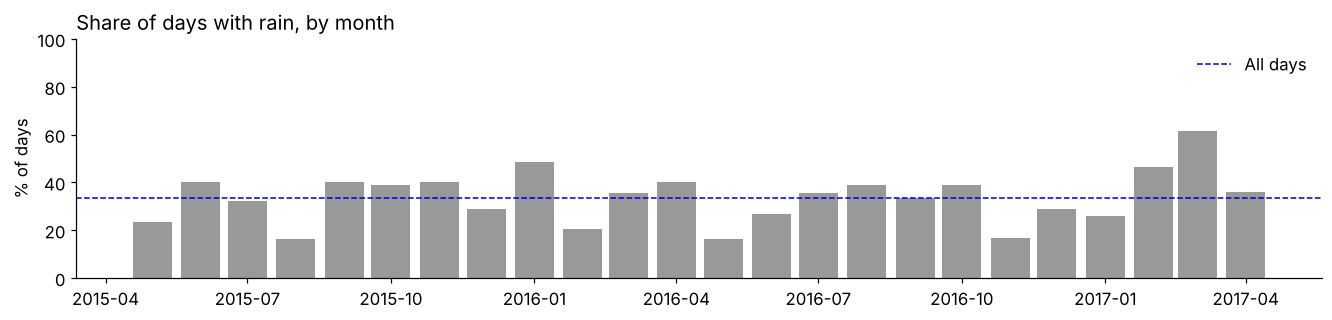

725 days, 02 May 2015 to 25 April 2017. It rained on 34% of them.


,rain_mm,rained,bureau_1_day_before,bureau_5_days_before
date,,,,
2016-06-01,0.2,0,74.0,51.0
2016-06-02,24.8,1,78.0,71.0
2016-06-03,65.6,1,90.0,73.0
2016-06-04,136.0,1,93.0,67.0
2016-06-05,0.2,0,44.0,55.0


In [2]:
weather = load("rain")
rained = (weather["rain_mm"] > 0.2).astype(float).to_frame("rained")

monthly = 100 * rained["rained"].resample("MS").mean()
fig, ax = plt.subplots(figsize=(12, 2.8), layout="constrained")
ax.bar(monthly.index, monthly, width=25, color="0.6")
ax.axhline(100 * rained["rained"].mean(), color="#0000CC", linestyle="--", linewidth=1, label="All days")
ax.set(title="Share of days with rain, by month", ylabel="% of days", ylim=(0, 100))
ax.legend(loc="upper right")
plt.show()
print(f"{len(rained)} days, {weather.index[0]:%d %B %Y} to {weather.index[-1]:%d %B %Y}. "
      f"It rained on {100 * rained['rained'].mean():.0f}% of them.")
display(weather[["rain_mm", "bureau_1_day_before", "bureau_5_days_before"]].join(rained.astype(int))
        .loc["2016-06-01":"2016-06-05", ["rain_mm", "rained", "bureau_1_day_before", "bureau_5_days_before"]])

The five rows are the storm of June 2016. The Bureau's two columns are in percent.

## Four forecasters of our own

Each one gives the probability of rain tomorrow, a number between 0 and 1, from the yes/no history up to today.

- **Long-run share** says the share of all past days that had rain. It hardly moves from one day to the next.
- **Same as today** says 1 after a rainy day and 0 after a dry one.
- **Share of last 7 days** says how many of the last seven days had rain, as a fraction.
- **Regression on 7 days** is a linear regression from the last seven days to the next.

We forecast every day of the second year, each time from all the days before it, and ask for two scores by name. The **Brier score** is the squared gap between the probability and what happened (1 for rain, 0 for none), averaged over days. Zero is perfect, and saying 50% every day scores 0.25. The **log loss** punishes confident mistakes much harder. We also count how often each forecaster was simply right, taking a probability above one half as "rain".

In [3]:
class RecentShare:
    def __init__(self, days=7):
        self.days = days

    def fit(self, history):
        self.share_ = float(np.asarray(history)[-self.days:].mean())
        return self

    def predict(self, dates):
        return np.full(len(dates), self.share_)


forecasters = {"Long-run share": Pipeline(NaiveForecaster(strategy="mean")),
               "Same as today": Pipeline(LastValueForecaster()),
               "Share of last 7 days": Pipeline(RecentShare(7)),
               "Regression on 7 days": Pipeline(LinearRegression(), window_length=7)}

first = 365   # one year of history before the first forecast
cases = cases_from_series(rained, origins=range(first, len(rained)), horizon=1, name="rain")
happened = np.array([case.observed["rained"].iloc[0] for case in cases])
runs = {name: pipeline.run(cases=cases, scores=["brier", "log_loss"], keep_data=True)
        for name, pipeline in forecasters.items()}


def probabilities(run):
    return np.array([np.nan if entry.forecast is None else entry.forecast.point[0, 0] for entry in run.cases])


def scores(run, score):
    return np.array([entry.result.metrics.get(score, np.nan) for entry in run.cases])


def summary(run, days=slice(None)):
    said, brier, log_loss = probabilities(run)[days], scores(run, "brier")[days], scores(run, "log_loss")[days]
    return {"Right on (% of days)": 100 * np.mean((said > 0.5) == (happened[days] == 1)),
            "Brier score": brier.mean(),
            "Log loss": log_loss.mean(),   # no number if any day has none
            "Days with no log loss": np.isnan(log_loss).sum()}


def show(table):
    table = table.round({"Right on (% of days)": 0, "Brier score": 3, "Log loss": 3})
    display(table.astype({"Right on (% of days)": int, "Days with no log loss": int}))


ours = pd.DataFrame({name: summary(run) for name, run in runs.items()}).T
show(ours)
regression = probabilities(runs["Regression on 7 days"])
print(f"{len(cases)} days forecast. It rained on {100 * happened.mean():.0f}% of them.")
print(f"The regression's forecasts run from {regression.min():.2f} to {regression.max():.2f}.")

brier = ours["Brier score"]
assert ours["Right on (% of days)"].idxmax() == "Same as today" and brier.idxmax() == "Same as today"
assert brier.idxmin() == "Regression on 7 days" and 0.08 < 1 - brier.min() / brier["Long-run share"] < 0.14

,Right on (% of days),Brier score,Log loss,Days with no log loss
Long-run share,66,0.224,0.639,0
Same as today,72,0.283,NaN,102
Share of last 7 days,59,0.257,NaN,15
Regression on 7 days,71,0.199,0.586,0


360 days forecast. It rained on 34% of them.
The regression's forecasts run from 0.08 to 0.72.


Two columns, two different winners.

**Same as today** is right on 72% of days, more than any of the others. It also has the worst Brier score, worse than the forecaster that says about one in three every single day. Both are true. It only ever says 0 or 1, so on the days it is wrong it is as wrong as a probability can be, and those days cost more than the right ones earn. Being right most often and giving the most useful probability are different skills. The long-run share makes the same point from the other side: it never once says rain, and is right on 66% of days.

**Regression on 7 days** has the best Brier score, 0.199 against 0.224 for the long-run share: 11% better. That is the edge our own modeling found.

## Where a score cannot be given

The log loss column has no number for two forecasters. And a linear regression is not built to return probabilities: nothing stops it going below 0 or above 1. With seven days it stayed between 0.08 and 0.72. Here is what happens when it looks back 14 days.

In [4]:
def notes(run, score):
    return [diagnostic.message for entry in run.cases for diagnostic in entry.result.diagnostics
            if diagnostic.name == f"metric_{score}" and str(diagnostic.status) in ("INCONCLUSIVE", "ERROR")]


def quote(note):
    print(textwrap.fill(f'TimeGym\'s note: "{note}"', 74, initial_indent="  ", subsequent_indent="  "), end="\n\n")


today = notes(runs["Same as today"], "log_loss")
wrong = int(np.sum((probabilities(runs["Same as today"]) > 0.5) != (happened == 1)))
print(f"Same as today: no log loss on {len(today)} of {len(cases)} days. It was wrong on {wrong} days.")
quote(today[0])

longer = Pipeline(LinearRegression(), window_length=14).run(cases=cases, scores=["brier", "log_loss"],
                                                           keep_data=True)
below = notes(longer, "brier")
print(f"Regression on 14 days: no Brier score on {len(below)} days. Lowest forecast: {probabilities(longer).min():.2f}.")
quote(below[0])


class ClippedRegression(LinearRegression):
    def predict(self, X):
        return np.clip(super().predict(X), 0.01, 0.99)   # keep the answer a probability


clipped = Pipeline(ClippedRegression(), window_length=14).run(cases=cases, scores=["brier", "log_loss"])
print(f"Clipped to between 0.01 and 0.99: no Brier score on {len(notes(clipped, 'brier'))} days.")
print(f"  Brier score {scores(clipped, 'brier').mean():.3f}, against {brier['Regression on 7 days']:.3f} with 7 days.")
assert len(today) == wrong == ours.loc["Same as today", "Days with no log loss"]
assert len(below) == int((probabilities(longer) < 0).sum()) > 0 and not notes(clipped, "brier")
assert scores(clipped, "brier").mean() > brier["Regression on 7 days"]

Same as today: no log loss on 102 of 360 days. It was wrong on 102 days.
  TimeGym's note: "a forecast of exactly 1 at position (0, 0) turned out
  wrong, so the log loss is infinite; pass eps, such as eps=1e-6, to clip
  forecasts to [eps, 1 - eps] first"



Regression on 14 days: no Brier score on 6 days. Lowest forecast: -0.08.
  TimeGym's note: "Score calculation raised ValueError: predicted must be
  between 0 and 1; got -0.00882844 at position (0, 0)"



Clipped to between 0.01 and 0.99: no Brier score on 0 days.
  Brier score 0.210, against 0.199 with 7 days.


Two different problems, each reported on the day it happened.

"Same as today" has no log loss on exactly the days it was wrong. It said rain was impossible, or certain, and the opposite happened, which makes the log loss infinite. Averaging the days that are left would give it a log loss of zero, the best there is, for the forecaster with the worst Brier score. The note is what keeps that number out of a report.

The 14-day regression forecast a negative chance of rain on six days. That is a fault in the forecaster, not a property of the score, so TimeGym records an error for those days and does not score them. Three lines fix it. With every day scored, the longer look-back turns out worse than seven days, so we keep the seven.

## The forecast that already exists

So far the story is "our regression beats the long-run share by 11%". Before building anything more, there is a forecast we have not scored: the one the weather service publishes. The column `bureau_1_day_before` holds the chance of rain the Bureau gave for each day in the forecast it issued the day before. Our forecasters need the rain record up to the start of the day they forecast, so the Bureau's number was out before ours could be made.

`ForecastRun.from_forecasts` scores forecasts made elsewhere: the same cases, the same output checks, the same scores. A day for which nothing was published goes in as `None`.

Days scored: 358. Days with no forecast: 2, each reported as:
  "ValueError: No forecast was recorded for this case"


,Right on (% of days),Brier score,Log loss,Days with no log loss
Long-run share,66,0.224,0.641,0
Same as today,72,0.282,NaN,101
Share of last 7 days,59,0.258,NaN,15
Regression on 7 days,72,0.199,0.587,0
"Bureau, issued the day before",84,0.105,0.334,0


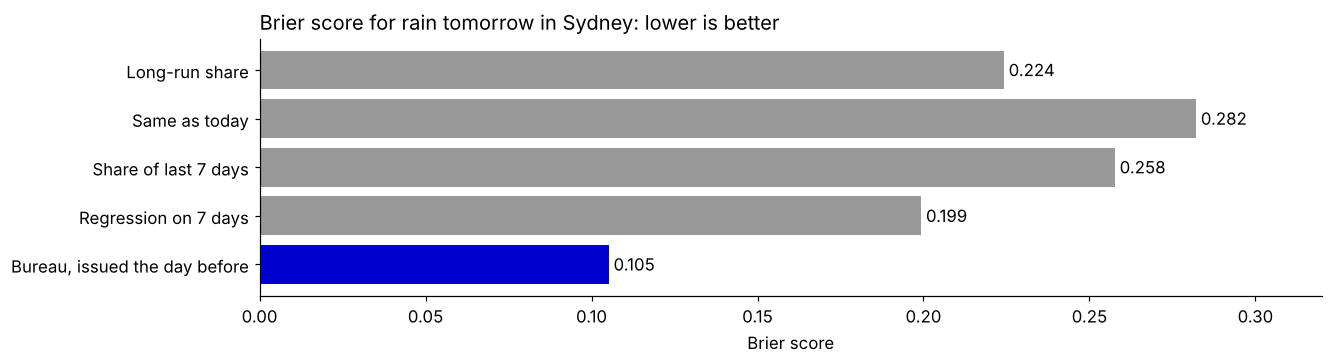

Better than the long-run share: Regression on 7 days 11%, Bureau 53%.


In [5]:
def bureau_run(column):
    said = weather[column].iloc[first:] / 100   # the source gives percent
    forecasts = [None if np.isnan(value) else [value] for value in said]
    return ForecastRun.from_forecasts(cases, forecasts, metadata={"model": column}, scores=["brier", "log_loss"])


bureau = bureau_run("bureau_1_day_before")
missing = [diagnostic.message for entry in bureau.cases for diagnostic in entry.result.diagnostics
           if str(diagnostic.status) == "ERROR"]
published = ~np.isnan(scores(bureau, "brier"))
print(f"Days scored: {published.sum()}. Days with no forecast: {len(missing)}, each reported as:")
print(f"  \"{missing[0]}\"")

# Compare on the days the Bureau published a forecast, so everyone is scored on the same days.
table = pd.DataFrame({name: summary(run, published) for name, run in runs.items()}).T
table.loc["Bureau, issued the day before"] = summary(bureau, published)
show(table)

colors = ["#0000CC" if name.startswith("Bureau") else "0.6" for name in table.index]
fig, ax = plt.subplots(figsize=(12, 3.2), layout="constrained")
ax.barh(table.index, table["Brier score"], color=colors)
ax.invert_yaxis()
for row, value in enumerate(table["Brier score"]):
    ax.text(value, row, f" {value:.3f}", va="center")
ax.set(title="Brier score for rain tomorrow in Sydney: lower is better", xlabel="Brier score", xlim=(0, 0.32))
plt.show()

gain = 1 - table["Brier score"] / table.loc["Long-run share", "Brier score"]
print(f"Better than the long-run share: Regression on 7 days {100 * gain['Regression on 7 days']:.0f}%, "
      f"Bureau {100 * gain['Bureau, issued the day before']:.0f}%.")
assert len(missing) == 2 and published.sum() == len(cases) - 2
assert 0.50 < gain["Bureau, issued the day before"] < 0.56 and 0.08 < gain["Regression on 7 days"] < 0.14

The Bureau's forecast scores 0.105. It is 53% better than the long-run share where our regression is 11% better, and it is right on 84% of days. No amount of tuning a regression on past rain will close that gap: the Bureau forecasts with weather models and measurements, and we forecast from a column of 0s and 1s. The honest conclusion of this project is to use the published forecast, and it took one cell to find out.

On two days the Bureau's forecast is missing from the data. They were reported as cases with no forecast and left out of the comparison for everyone, so the table compares like with like.

## Is its 70% really 70%?

A good Brier score could still hide a forecast that is too bold or too timid. The run kept every probability, so we can group the days by what the Bureau said and count how often it rained.

In [6]:
said = probabilities(bureau)[published]
groups = pd.cut(said, [-0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
                labels=["0 to 10%", "10 to 30%", "30 to 50%", "50 to 70%", "70 to 90%", "90 to 100%"])
calibration = pd.DataFrame({"said": 100 * said, "rained": 100 * happened[published]}).groupby(groups, observed=True).agg(
    **{"Days": ("said", "size"), "Bureau said, on average (%)": ("said", "mean"), "It rained on (%)": ("rained", "mean")})
display(calibration.rename_axis("Chance of rain given").round(0).astype(int))
gap = (calibration["Bureau said, on average (%)"] - calibration["It rained on (%)"]).abs()
assert gap.max() < 12 and calibration["It rained on (%)"].is_monotonic_increasing

,Days,"Bureau said, on average (%)",It rained on (%)
Chance of rain given,,,
0 to 10%,130,4,2
10 to 30%,72,20,19
30 to 50%,43,39,37
50 to 70%,46,62,59
70 to 90%,49,81,90
90 to 100%,18,94,100


When the Bureau said about 20%, it rained on 19% of those days. When it said about 60%, it rained on 59%. At the top it is slightly cautious: of the days given 70 to 90%, nine in ten had rain. Its probabilities mean what they say, which is what makes them usable for a decision such as whether to pour concrete tomorrow.

## How far ahead does it hold?

The same column exists for forecasts issued up to five days before. One loop scores them all, each on the days it was published.

In [7]:
columns = {"On the day itself": "bureau_same_day", "1 day before": "bureau_1_day_before",
           "2 days before": "bureau_2_days_before", "3 days before": "bureau_3_days_before",
           "4 days before": "bureau_4_days_before", "5 days before": "bureau_5_days_before"}
by_lead = pd.Series({label: np.nanmean(scores(bureau_run(column), "brier")) for label, column in columns.items()})
leads = pd.DataFrame({"Brier score": by_lead.round(3),
                      "Better than the long-run share (%)": (100 * (1 - by_lead / brier["Long-run share"])).round(0).astype(int)})
display(leads.rename_axis("Bureau forecast issued"))
print(f"Our regression, made as the day begins: {brier['Regression on 7 days']:.3f}.")
assert by_lead.is_monotonic_increasing and by_lead.iloc[-1] < brier["Regression on 7 days"]

,Brier score,Better than the long-run share (%)
Bureau forecast issued,,
On the day itself,0.093,59
1 day before,0.105,53
2 days before,0.113,49
3 days before,0.133,40
4 days before,0.165,26
5 days before,0.173,23


Our regression, made as the day begins: 0.199.


The Bureau's forecast gets worse with every day of lead, as it should. Even so, the forecast it issued five days before beats our regression, which has the rain record of those five extra days to work from. "On the day itself" is the forecast issued on the date the 24 hours start; the source does not say at what hour, so we do not lean on it.

## What TimeGym added

- A yes/no outcome handled as it is: a series of 0s and 1s, forecasts that are probabilities, and the two standard scores asked for by name.
- "Right on 72% of days" and "worst Brier score" for the same forecaster, side by side from one run.
- A note on every day where a score could not be given. One kept a meaningless perfect log loss out of the table; the other caught a regression forecasting a negative chance of rain.
- A way to score a forecast we did not make, on our own cases. That one cell changed the project's conclusion.
- The two days with no published forecast were reported, so everyone could be scored on the same 358 days.

## Change one thing

- Count a reading of exactly 0.2 millimeters as rain (`>= 0.2`). 43 days change sides and the Bureau's score gets worse, because its forecast is for the other definition. What counts as the event is part of the forecast.
- Shorten the regression's look-back: `window_length=3` does slightly better than 7.
- Ask a different question: `weather["rain_mm"] > 5` is a properly wet day. Use `ClippedRegression`; the plain one goes below zero again, and TimeGym will tell you on which days. The Bureau's column cannot be scored on this question, because its chance is for any rain at all.
- Score what a mistake costs you: `scores={"cost": my_function}`, where the function takes `observed` and `predicted`.
- Another city: `load("rain", full=True)` downloads all 422 stations (26 MB), with the Bureau's station number above each column. `load("rain", full=True)["86282"]` is Melbourne Airport.

**What this doesn't show.** One city and one year of forecasts. Our forecasters see only whether it rained on past days, so the comparison with the Bureau is not a fair fight, and is not meant to be one: the point is to measure the gap before spending effort. The data gives the day each forecast was issued, not the hour. TimeGym scores yes/no outcomes; it has nothing specific for outcomes with more than two categories, such as "dry, showers or heavy rain".

**Related:** [Yes/no outcomes](../docs/api/diagnostics.md#yesno-outcomes) in the reference, [Real-data forecasts](../tutorials/07_real_data_forecasts.ipynb) for cases cut from your own series, and [When there is no score](../docs/concepts/scope.md#when-there-is-no-score). More examples are on the [examples page](../docs/examples.md).